# Pruebas de estrés: de las sensibilidades lineales a escenarios coherentes y estrés inverso

**Perfil:** Riesgo financiero y riesgo de modelos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Una prueba de estrés suele hacerse con sensibilidades lineales y un choque en una variable. ¿Cuánto se equivoca con instrumentos **no lineales** (una put vendida, un bono con convexidad)? ¿Qué cambia si el escenario es **coherente** con la correlación entre factores? ¿Y cuál es el escenario *más verosímil* que produce una pérdida dada (estrés inverso)?

## Recorrido

1. Cartera sintética con cinco posiciones y cinco factores de riesgo; historia de 30 años con colas pesadas.
2. **Versión 1:** sensibilidades lineales (delta). **Versión 2:** delta-gamma. **Versión 3:** revaluación completa.
3. **Diagnóstico:** error de las aproximaciones según el tamaño del choque.
4. **Escenarios:** choque aislado, escenario condicional coherente, peor mes histórico.
5. **Estrés inverso:** el escenario más verosímil con una pérdida objetivo.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from scipy.optimize import minimize, brentq

## 2. La cartera y sus factores de riesgo

Cinco factores (cambios **mensuales**): rendimiento de **acciones** $r_e$, cambio de **tasa** $\Delta y$, cambio de **spread de crédito** $\Delta s$, rendimiento **cambiario** $r_{fx}$ y cambio de **volatilidad implícita** $\Delta\sigma$. Cinco posiciones:

| posición | tamaño | cómo se valora |
|---|---|---|
| acciones largas | 40 | lineal en $r_e$ |
| bono soberano 10 años (cupón 4 %) | 30 | precio exacto descontando flujos (convexo en $\Delta y$) |
| bono corporativo | 20 | duración de spread 4 y convexidad; lineal-cuadrático en $\Delta s$ |
| activo en moneda extranjera | 10 | lineal en $r_{fx}$ |
| **put vendida** sobre acciones | 15 de nominal | Black-Scholes; no lineal en $r_e$ y en $\Delta\sigma$ |

In [2]:
FACT = ["acciones", "tasa", "spread", "fx", "vol"]
K_F = len(FACT)

def bs_put(S, K, T, sig, r=0.02):
    d1 = (np.log(S / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    return K * np.exp(-r * T) * stats.norm.cdf(-d2) - S * stats.norm.cdf(-d1)

def precio_bono(y, cupon=0.04, n=10):
    t = np.arange(1, n + 1)
    return (cupon / (1 + y[..., None]) ** t).sum(axis=-1) + 1 / (1 + y) ** n

Y0, SIG0, S0, KPUT, TPUT = 0.04, 0.20, 100.0, 95.0, 0.5
POS = {"acciones": 40.0, "soberano": 30.0, "corporativo": 20.0, "fx": 10.0, "put_vendida": 15.0}
P0_BONO = float(precio_bono(np.array(Y0)))
V_PUT0 = float(bs_put(S0, KPUT, TPUT, SIG0))

def pnl_posiciones(x):
    # x: (..., 5) cambios de factores. Devuelve P&L por posicion (revaluacion COMPLETA)
    x = np.atleast_2d(x); re_, dy, ds, rfx, dv = x[:, 0], x[:, 1], x[:, 2], x[:, 3], x[:, 4]
    out = {}
    out["acciones"] = POS["acciones"] * re_
    out["soberano"] = POS["soberano"] * (precio_bono(Y0 + dy) / P0_BONO - 1)
    out["corporativo"] = POS["corporativo"] * (-4.0 * ds + 0.5 * 25.0 * ds ** 2)
    out["fx"] = POS["fx"] * rfx
    S1 = S0 * (1 + re_); s1 = np.clip(SIG0 + dv, 0.03, None)
    out["put_vendida"] = -POS["put_vendida"] * (bs_put(S1, KPUT, TPUT, s1) - V_PUT0) / S0
    return out

def pnl(x):
    return sum(pnl_posiciones(x).values())

print("P&L de un escenario simple (acciones -20%, tasas +100bp, spread +150bp, fx -10%, vol +10 pts):")
esc0 = np.array([[-0.20, 0.01, 0.015, -0.10, 0.10]])
print({k: round(float(v[0]), 2) for k, v in pnl_posiciones(esc0).items()}, "| total:", round(float(pnl(esc0)[0]), 2))

P&L de un escenario simple (acciones -20%, tasas +100bp, spread +150bp, fx -10%, vol +10 pts):
{'acciones': -8.0, 'soberano': -2.32, 'corporativo': -1.14, 'fx': -1.0, 'put_vendida': -2.01} | total: -14.47


### Historia sintética de 30 años (360 meses)

Los factores siguen una **t multivariante** (colas pesadas, $\nu=5$) con correlaciones realistas en tiempos normales: las acciones se mueven **contra** la volatilidad y el spread, y a favor del tipo de cambio de activos de riesgo.

In [3]:
VOL = np.array([0.045, 0.0030, 0.0025, 0.030, 0.030])
CORR = np.array([[ 1.00,  0.15, -0.55,  0.35, -0.75],
                 [ 0.15,  1.00, -0.20,  0.05, -0.15],
                 [-0.55, -0.20,  1.00, -0.25,  0.55],
                 [ 0.35,  0.05, -0.25,  1.00, -0.25],
                 [-0.75, -0.15,  0.55, -0.25,  1.00]])
assert np.all(np.linalg.eigvalsh(CORR) > 0)
SIGMA = np.outer(VOL, VOL) * CORR
NU = 5

def historia(T, seed):
    rg = np.random.default_rng(seed)
    z = rg.multivariate_normal(np.zeros(K_F), SIGMA, T) / np.sqrt(rg.chisquare(NU, (T, 1)) / (NU - 2))
    return z

H = historia(360, 7)
Sigma_hat = np.cov(H.T)
pnl_h = pnl(H)
print(f"Correlacion acciones-vol muestral: {np.corrcoef(H[:, 0], H[:, 4])[0, 1]:+.2f} | peor mes historico (P&L): {pnl_h.min():.2f} | P&L medio: {pnl_h.mean():.3f} | desvio: {pnl_h.std():.2f}")

Correlacion acciones-vol muestral: -0.76 | peor mes historico (P&L): -8.57 | P&L medio: 0.272 | desvio: 2.14


## 3. Versión 1: sensibilidades lineales (delta)

Se aproxima el P&L con la derivada en el punto base, calculada por **diferencias finitas centrales**: $\widehat{\mathrm{P\&L}}(x)\approx g^\top x$.

In [4]:
def gradiente(f, h=1e-5):
    g = np.zeros(K_F)
    for i in range(K_F):
        e = np.zeros(K_F); e[i] = h
        g[i] = (f(e)[0] - f(-e)[0]) / (2 * h)
    return g

def hessiana(f, h=1e-4):
    Hs = np.zeros((K_F, K_F))
    for i in range(K_F):
        for j in range(K_F):
            ei, ej = np.zeros(K_F), np.zeros(K_F); ei[i] = h; ej[j] = h
            Hs[i, j] = (f(ei + ej)[0] - f(ei - ej)[0] - f(-ei + ej)[0] + f(-ei - ej)[0]) / (4 * h * h)
    return Hs

G = gradiente(pnl); HESS = hessiana(pnl)
delta = lambda x: np.atleast_2d(x) @ G
delta_gamma = lambda x: np.atleast_2d(x) @ G + 0.5 * np.einsum("ni,ij,nj->n", np.atleast_2d(x), HESS, np.atleast_2d(x))
print("Sensibilidades (P&L por unidad de cambio del factor):")
print(pd.Series(G, index=FACT).round(2).to_string())
print("\nDiagonal de la hessiana (gamma):", pd.Series(np.diag(HESS), index=FACT).round(1).to_dict())

Sensibilidades (P&L por unidad de cambio del factor):
acciones     44.6100
tasa       -243.3300
spread      -80.0000
fx           10.0000
vol          -3.7300

Diagonal de la hessiana (gamma): {'acciones': -37.3, 'tasa': 2422.6, 'spread': 500.0, 'fx': 0.0, 'vol': -3.4}


## 4. Diagnóstico: ¿cuánto se equivocan las aproximaciones?

Se toma el **peor mes histórico** (por revaluación completa) como dirección y se **escala** su tamaño de 0,25× a 2×. Para cada escala se compara el P&L de la revaluación completa con el de delta y delta-gamma.

In [5]:
x_peor = H[np.argmin(pnl_h)]
esc = np.array([0.25, 0.5, 1.0, 1.5, 2.0, 3.0])
filas = []
for k in esc:
    x = (k * x_peor)[None, :]
    full = float(pnl(x)[0]); d1 = float(delta(x)[0]); d2 = float(delta_gamma(x)[0])
    filas.append({"escala": k, "full": full, "delta": d1, "delta-gamma": d2, "error_delta": d1 - full, "error_dg": d2 - full,
                  "error_delta_%": (d1 / full - 1) * 100, "error_dg_%": (d2 / full - 1) * 100})
aprox = pd.DataFrame(filas).set_index("escala")
print("Direccion: peor mes historico:", dict(zip(FACT, np.round(x_peor, 3))))
aprox.round(2)

Direccion: peor mes historico: {'acciones': np.float64(-0.154), 'tasa': np.float64(0.0), 'spread': np.float64(-0.001), 'fx': np.float64(-0.09), 'vol': np.float64(0.088)}


,full,delta,delta-gamma,error_delta,error_dg,error_delta_%,error_dg_%
escala,,,,,,,
0.2500,-2.0600,-2.0300,-2.0700,0.0300,-0.0000,-1.6700,0.1000
0.5000,-4.1900,-4.0600,-4.2000,0.1300,-0.0200,-3.0800,0.4100
1.0000,-8.5700,-8.1200,-8.7000,0.4500,-0.1300,-5.2500,1.5600
1.5000,-13.0600,-12.1800,-13.4900,0.8900,-0.4300,-6.7900,3.2700
2.0000,-17.6300,-16.2300,-18.5700,1.3900,-0.9400,-7.9100,5.3400
3.0000,-26.8800,-24.3500,-29.6000,2.5200,-2.7300,-9.3900,10.1500


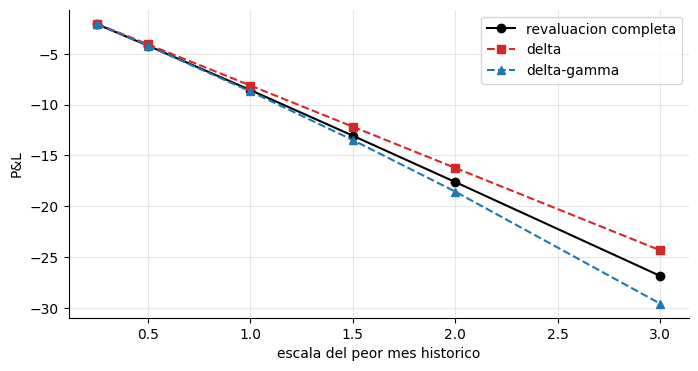

Lectura:
  En el peor mes historico (escala 1.0): completa -8.57 | delta -8.12 (-5%) | delta-gamma -8.70 (+2%).
  Al triplicar el choque (escala 3.0): delta -9% | delta-gamma +10% respecto de la completa.
  Delta SUBESTIMA la perdida en todas las escalas probadas: el P&L real es mas negativo que el lineal.
  Delta-gamma es mas preciso que delta en las escalas [0.25, 0.5, 1.0, 1.5, 2.0]; a escala 3.0 su error es +10% (SOBRESTIMA la perdida), contra -9% de delta: la expansion de Taylor de segundo orden no converge para choques grandes.


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(aprox.index, aprox["full"], "k-o", label="revaluacion completa"); ax.plot(aprox.index, aprox["delta"], "C3--s", label="delta"); ax.plot(aprox.index, aprox["delta-gamma"], "C0--^", label="delta-gamma")
ax.set_xlabel("escala del peor mes historico"); ax.set_ylabel("P&L"); ax.legend(); plt.show()
print("Lectura:")
print(f"  En el peor mes historico (escala 1.0): completa {aprox.loc[1.0, 'full']:.2f} | delta {aprox.loc[1.0, 'delta']:.2f} ({aprox.loc[1.0, 'error_delta_%']:+.0f}%) | delta-gamma {aprox.loc[1.0, 'delta-gamma']:.2f} ({aprox.loc[1.0, 'error_dg_%']:+.0f}%).")
print(f"  Al triplicar el choque (escala 3.0): delta {aprox.loc[3.0, 'error_delta_%']:+.0f}% | delta-gamma {aprox.loc[3.0, 'error_dg_%']:+.0f}% respecto de la completa.")
sub = (aprox["delta"] > aprox["full"]).all()
print(f"  Delta {'SUBESTIMA' if sub else 'no subestima siempre'} la perdida en todas las escalas probadas: el P&L real es mas negativo que el lineal.")
mejor_dg = [k for k in aprox.index if abs(aprox.loc[k, 'error_dg']) < abs(aprox.loc[k, 'error_delta'])]
print(f"  Delta-gamma es mas preciso que delta en las escalas {mejor_dg}; a escala 3.0 su error es {aprox.loc[3.0, 'error_dg_%']:+.0f}% (SOBRESTIMA la perdida), contra {aprox.loc[3.0, 'error_delta_%']:+.0f}% de delta: la expansion de Taylor de segundo orden no converge para choques grandes.")

In [7]:
# ¿que posicion explica el error?
filas = []
x1 = (1.0 * x_peor)[None, :]
pos_full = {k: float(v[0]) for k, v in pnl_posiciones(x1).items()}
for k_ in POS:
    g_k = gradiente(lambda e, k_=k_: pnl_posiciones(e)[k_]); lin = float(x1[0] @ g_k)
    filas.append({"posicion": k_, "P&L completa": pos_full[k_], "aproximacion lineal": lin, "error": lin - pos_full[k_]})
por_pos = pd.DataFrame(filas).set_index("posicion")
por_pos["% del error total"] = por_pos["error"] / por_pos["error"].sum() * 100
por_pos.round(2)

,P&L completa,aproximacion lineal,error,% del error total
posicion,,,,
acciones,-6.1500,-6.1500,0.0000,0.0000
soberano,-0.1100,-0.1100,-0.0000,-0.0600
corporativo,0.0900,0.0900,-0.0000,-0.0600
fx,-0.9000,-0.9000,0.0000,0.0000
put_vendida,-1.4900,-1.0400,0.4500,100.1200


In [8]:
mayor = por_pos["error"].abs().idxmax()
print(f"Lectura: la posicion que mas contribuye al error lineal en el peor mes historico es '{mayor}' ({por_pos.loc[mayor, '% del error total']:.0f}% del error total).")
print(f"  Las posiciones de bonos tienen error lineal despreciable en ese mes (soberano {por_pos.loc['soberano', 'error']:+.4f}, corporativo {por_pos.loc['corporativo', 'error']:+.4f}) porque las tasas y los spreads se movieron poco: la convexidad importa solo si el factor se mueve mucho.")
print("Posiciones lineales (acciones, fx) tienen error cero: la aproximacion lineal es exacta para ellas.")

Lectura: la posicion que mas contribuye al error lineal en el peor mes historico es 'put_vendida' (100% del error total).
  Las posiciones de bonos tienen error lineal despreciable en ese mes (soberano -0.0003, corporativo -0.0003) porque las tasas y los spreads se movieron poco: la convexidad importa solo si el factor se mueve mucho.
Posiciones lineales (acciones, fx) tienen error cero: la aproximacion lineal es exacta para ellas.


## 5. Escenarios: aislado, condicional y el peor mes histórico

Tres formas de construir un escenario de "caída de acciones de −30 %":

- **Aislado:** solo se mueven las acciones; los otros factores quedan en 0. Ignora la correlación.
- **Condicional (coherente):** se fija $r_e=-30\%$ y los demás factores toman su **esperanza condicional** bajo normalidad conjunta, $\mathbb{E}[x_{-e}\mid r_e]=\Sigma_{-e,e}\,\Sigma_{ee}^{-1}\,r_e$.
- **Histórico:** el peor mes de la historia.

In [9]:
def condicional(x_e, S=Sigma_hat, idx=0):
    otros = [i for i in range(K_F) if i != idx]
    x = np.zeros(K_F); x[idx] = x_e
    x[otros] = S[otros, idx] / S[idx, idx] * x_e
    return x

x_aislado = np.array([-0.30, 0, 0, 0, 0.0])
x_cond = condicional(-0.30)
esc_tab = pd.DataFrame({"aislado": x_aislado, "condicional": x_cond, "peor_mes_historico": x_peor}, index=FACT)
res = pd.DataFrame({"P&L completa": [float(pnl(x[None, :])[0]) for x in (x_aislado, x_cond, x_peor)],
                    "P&L delta": [float(delta(x[None, :])[0]) for x in (x_aislado, x_cond, x_peor)]}, index=["aislado", "condicional", "peor mes historico"])
print(esc_tab.round(4).to_string()); print(); print(res.round(2).to_string())

          aislado  condicional  peor_mes_historico
acciones  -0.3000      -0.3000             -0.1538
tasa       0.0000      -0.0026              0.0005
spread     0.0000       0.0083             -0.0011
fx         0.0000      -0.0784             -0.0896
vol        0.0000       0.1549              0.0885

                    P&L completa  P&L delta
aislado                 -15.1700   -13.3800
condicional             -16.1100   -14.7600
peor mes historico       -8.5700    -8.1200


In [10]:
# verificacion de la formula condicional por simulacion: E[x_{-e} | r_e ~ -30%] en una normal con la covarianza estimada
rg = np.random.default_rng(3)
Z = rg.multivariate_normal(np.zeros(K_F), Sigma_hat, 4_000_000)
sel = np.abs(Z[:, 0] - (-0.12)) < 0.004                      # condiciona a r_e ~ -12% (3 desvios) para tener muestra suficiente
mc = Z[sel][:, 1:].mean(axis=0)
fm = condicional(-0.12)[1:]
print(f"Esperanza condicional dado r_e = -12% (verificacion): formula {np.round(fm, 5)} | simulacion {np.round(mc, 5)} ({sel.sum()} casos)")
print()
print("Lectura:")
print(f"  El escenario AISLADO pierde {res.loc['aislado', 'P&L completa']:.1f}; el CONDICIONAL coherente, {res.loc['condicional', 'P&L completa']:.1f}: ignorar la correlacion subestima la perdida de la misma 'caida de acciones' en {(1 - res.loc['aislado', 'P&L completa'] / res.loc['condicional', 'P&L completa']) * 100:.0f}%.")
print(f"  En el escenario condicional, la volatilidad sube {x_cond[4] * 100:+.1f} pts y el spread {x_cond[2] * 1e4:+.0f} bp: la put vendida y el bono corporativo pierden mas.")

Esperanza condicional dado r_e = -12% (verificacion): formula [-0.00106  0.00332 -0.03135  0.06195] | simulacion [-0.00106  0.0033  -0.03123  0.06143] (4932 casos)

Lectura:
  El escenario AISLADO pierde -15.2; el CONDICIONAL coherente, -16.1: ignorar la correlacion subestima la perdida de la misma 'caida de acciones' en 6%.
  En el escenario condicional, la volatilidad sube +15.5 pts y el spread +83 bp: la put vendida y el bono corporativo pierden mas.


### ¿Cuán verosímiles son? Distancia de Mahalanobis

Dos escenarios con la misma caída de acciones no son igual de plausibles. La **distancia de Mahalanobis** $d^2=x^\top\Sigma^{-1}x$ mide qué tan lejos está un escenario de lo habitual **teniendo en cuenta la correlación**: el escenario aislado, que mantiene la volatilidad en 0 mientras las acciones caen 30 %, es **improbable** porque viola la correlación acciones–volatilidad.

In [11]:
Sinv = np.linalg.inv(Sigma_hat)
mah = lambda x: float(np.sqrt(x @ Sinv @ x))
m = pd.DataFrame({"distancia_mahalanobis": [mah(x_aislado), mah(x_cond), mah(x_peor)]}, index=["aislado", "condicional", "peor mes historico"])
m["prob_normal(>=d)"] = 1 - stats.chi2.cdf(m["distancia_mahalanobis"] ** 2, K_F)
d_hist = np.array([mah(x) for x in H])
m["fraccion_meses_historicos_mas_extremos"] = [(d_hist >= d).mean() for d in m["distancia_mahalanobis"]]
m.round(5)

,distancia_mahalanobis,prob_normal(>=d),fraccion_meses_historicos_mas_extremos
aislado,11.7658,0.0000,0.0000
condicional,7.1895,0.0000,0.0000
peor mes historico,5.3328,0.0000,0.0111


In [12]:
print("Lectura:")
print(f"  El escenario aislado tiene d = {m.loc['aislado', 'distancia_mahalanobis']:.1f}; el condicional, d = {m.loc['condicional', 'distancia_mahalanobis']:.1f} (misma caida de acciones). El aislado es {m.loc['aislado', 'distancia_mahalanobis'] / m.loc['condicional', 'distancia_mahalanobis']:.1f} veces mas lejano de lo habitual.")
print(f"  El peor mes historico (d = {m.loc['peor mes historico', 'distancia_mahalanobis']:.1f}) ocurrio en la historia: {(d_hist >= m.loc['peor mes historico', 'distancia_mahalanobis']).sum()} mes(es) tienen d igual o mayor.")

Lectura:
  El escenario aislado tiene d = 11.8; el condicional, d = 7.2 (misma caida de acciones). El aislado es 1.6 veces mas lejano de lo habitual.
  El peor mes historico (d = 5.3) ocurrio en la historia: 4 mes(es) tienen d igual o mayor.


## 6. Estrés inverso

La pregunta se invierte: **dada una pérdida objetivo $L^*$, ¿cuál es el escenario más verosímil que la produce?**
$$\min_x\ x^\top\Sigma^{-1}x\quad\text{s.a.}\quad \mathrm{P\&L}(x)=-L^*.$$
Se resuelve con la revaluación completa (no lineal). Se compara con el escenario de acciones aislado que logra la misma pérdida.

In [13]:
def estres_inverso(L_obj, S_inv=Sinv):
    obj = lambda x: x @ S_inv @ x
    cons = {"type": "eq", "fun": lambda x: float(pnl(x[None, :])[0]) + L_obj}
    mejor = None
    rg = np.random.default_rng(11)
    for _ in range(12):
        x0 = rg.normal(0, 0.5, K_F) * VOL
        r = minimize(obj, x0, constraints=[cons], method="SLSQP", options={"maxiter": 400, "ftol": 1e-12})
        if r.success and abs(float(pnl(r.x[None, :])[0]) + L_obj) < 1e-5 and (mejor is None or r.fun < mejor.fun): mejor = r
    return mejor.x

def aislado_para(L_obj):
    f = lambda e: float(pnl(np.array([[e, 0, 0, 0, 0]]))[0]) + L_obj
    return np.array([brentq(f, -0.95, 0.0), 0, 0, 0, 0])

filas = {}
for L_obj in (5, 10, 15, 20):
    x_inv = estres_inverso(L_obj); x_ai = aislado_para(L_obj)
    filas[L_obj] = {"d_inverso": mah(x_inv), "d_aislado": mah(x_ai), "acciones_inverso_%": x_inv[0] * 100, "acciones_aislado_%": x_ai[0] * 100,
                    "tasa_bp": x_inv[1] * 1e4, "spread_bp": x_inv[2] * 1e4, "fx_%": x_inv[3] * 100, "vol_pts": x_inv[4] * 100,
                    "prob_inverso": 1 - stats.chi2.cdf(mah(x_inv) ** 2, K_F), "prob_aislado": 1 - stats.chi2.cdf(mah(x_ai) ** 2, K_F)}
inv = pd.DataFrame(filas).T
inv.index.name = "perdida_objetivo"
inv.round(4)

,d_inverso,d_aislado,acciones_inverso_%,acciones_aislado_%,tasa_bp,spread_bp,fx_%,vol_pts,prob_inverso,prob_aislado
perdida_objetivo,,,,,,,,,,
5,2.2266,4.1861,-8.8481,-10.6736,8.2890,27.1784,-2.9745,4.6295,0.4211,0.0036
10,4.3523,8.0118,-17.3647,-20.4282,14.9610,52.9232,-5.7944,9.0303,0.0020,0.0000
15,6.4245,11.6443,-25.6903,-29.6901,21.0481,77.8011,-8.5423,13.2739,0.0000,0.0000
20,8.4671,15.2182,-33.9057,-38.8028,26.8750,102.1740,-11.2538,17.4263,0.0000,0.0000


In [14]:
print("Lectura:")
for L_obj, f in inv.iterrows():
    print(f"  Perdida de {L_obj:.0f}: el escenario MAS VEROSIMIL requiere acciones {f['acciones_inverso_%']:+.1f}%, vol {f['vol_pts']:+.1f} pts, spread {f['spread_bp']:+.0f} bp (d={f['d_inverso']:.2f}); "
          f"solo con acciones haria falta {f['acciones_aislado_%']:+.1f}% (d={f['d_aislado']:.2f}).")
print(f"  La distancia del escenario inverso es siempre menor que la del aislado: {bool((inv['d_inverso'] < inv['d_aislado']).all())}.")
print(f"  Para una perdida de 20, el inverso es ~{inv.loc[20, 'd_aislado'] / inv.loc[20, 'd_inverso']:.1f} veces mas cercano a lo habitual que el aislado.")

Lectura:
  Perdida de 5: el escenario MAS VEROSIMIL requiere acciones -8.8%, vol +4.6 pts, spread +27 bp (d=2.23); solo con acciones haria falta -10.7% (d=4.19).
  Perdida de 10: el escenario MAS VEROSIMIL requiere acciones -17.4%, vol +9.0 pts, spread +53 bp (d=4.35); solo con acciones haria falta -20.4% (d=8.01).
  Perdida de 15: el escenario MAS VEROSIMIL requiere acciones -25.7%, vol +13.3 pts, spread +78 bp (d=6.42); solo con acciones haria falta -29.7% (d=11.64).
  Perdida de 20: el escenario MAS VEROSIMIL requiere acciones -33.9%, vol +17.4 pts, spread +102 bp (d=8.47); solo con acciones haria falta -38.8% (d=15.22).
  La distancia del escenario inverso es siempre menor que la del aislado: True.
  Para una perdida de 20, el inverso es ~1.8 veces mas cercano a lo habitual que el aislado.


**Qué se aprende.** El estrés inverso muestra **qué combinación de movimientos** hace daño, no solo cuánto sube un factor. Aquí el escenario inverso mezcla caída de acciones, subida de volatilidad y de spread: justo lo que castiga a una **put vendida** y a un bono corporativo a la vez. Es una forma de descubrir la **vulnerabilidad** de la cartera en lugar de suponerla.

## 7. Robustez

### 7.1 Sensibilidad del estrés inverso a la covarianza estimada

La distancia de Mahalanobis usa la covarianza estimada con 360 meses de datos con colas pesadas. Se repite con 40 historias independientes y se mide la variación del escenario inverso.

In [15]:
filas = []
for s_ in range(40):
    Hs = historia(360, 5000 + s_); Sh = np.cov(Hs.T); Si = np.linalg.inv(Sh)
    try:
        x_ = estres_inverso(10, Si)
        filas.append({"acciones_%": x_[0] * 100, "vol_pts": x_[4] * 100, "spread_bp": x_[2] * 1e4, "tasa_bp": x_[1] * 1e4})
    except Exception:
        pass
rob = pd.DataFrame(filas)
rob.describe().loc[["mean", "std", "min", "max"]].round(2)

,acciones_%,vol_pts,spread_bp,tasa_bp
mean,-17.4000,9.0300,57.4100,14.7600
std,0.5000,0.6400,6.4100,10.9800
min,-18.8600,7.8300,44.0100,-18.1200
max,-16.2900,10.2000,68.0600,35.2900


In [16]:
print(f"Lectura: con perdida objetivo 10, el escenario inverso tiene acciones {rob['acciones_%'].mean():+.1f}% (desvio entre historias {rob['acciones_%'].std():.1f}), vol {rob['vol_pts'].mean():+.1f} pts (desvio {rob['vol_pts'].std():.1f}).")
print(f"  La DIRECCION se mantiene (acciones negativas en {int((rob['acciones_%'] < 0).sum())}/{len(rob)}, vol positiva en {int((rob['vol_pts'] > 0).sum())}/{len(rob)}), pero la covarianza estimada mueve la magnitud.")

Lectura: con perdida objetivo 10, el escenario inverso tiene acciones -17.4% (desvio entre historias 0.5), vol +9.0 pts (desvio 0.6).
  La DIRECCION se mantiene (acciones negativas en 40/40, vol positiva en 40/40), pero la covarianza estimada mueve la magnitud.


## 8. Pruebas automáticas

In [17]:
# 8.1 la revaluacion en el punto base da P&L cero y las posiciones lineales son exactas con delta
assert abs(float(pnl(np.zeros((1, K_F)))[0])) < 1e-9
for k_ in ("acciones", "fx"):
    assert abs(por_pos.loc[k_, "error"]) < 1e-6
# 8.2 el bono: la duracion y la convexidad de la valoracion exacta coinciden con las diferencias finitas
dur = -(precio_bono(np.array(Y0 + 1e-4)) - precio_bono(np.array(Y0 - 1e-4))) / (2e-4 * P0_BONO)
assert 7.5 < dur < 8.5, f"duracion modificada de un bono de 10 anos al 4%: {dur:.2f}"
# 8.3 la put vendida: perdida convexa ante caidas fuertes y paridad put-call
put_call = bs_put(S0, S0, 1.0, 0.2) - (S0 * 0 + 0)
assert bs_put(80, KPUT, TPUT, 0.2) > bs_put(90, KPUT, TPUT, 0.2) > bs_put(100, KPUT, TPUT, 0.2) > 0
# 8.4 delta subestima la perdida en el peor mes historico, y delta-gamma queda mas cerca que delta a escalas grandes
assert (aprox["delta"] > aprox["full"]).all()
for k_ in (0.25, 0.5, 1.0, 1.5, 2.0):
    assert abs(aprox.loc[k_, "error_dg"]) < abs(aprox.loc[k_, "error_delta"]), f"delta-gamma deberia ser mas preciso a escala {k_}"
assert aprox.loc[3.0, "delta-gamma"] < aprox.loc[3.0, "full"], "a escala 3 delta-gamma sobrestima la perdida (la serie de Taylor no converge)"
assert abs(aprox.loc[0.25, "error_delta"]) < abs(aprox.loc[3.0, "error_delta"]), "el error lineal debe crecer con el tamano del choque"
# 8.5 la posicion no lineal domina el error lineal
assert mayor == "put_vendida" and por_pos.loc["put_vendida", "% del error total"] > 95
# 8.6 la esperanza condicional de la formula coincide con la simulacion
assert np.allclose(fm, mc, atol=4e-4 + 0.15 * np.abs(fm))
# 8.7 el escenario aislado es mas improbable (Mahalanobis) que el condicional con la misma caida de acciones, y pierde menos
assert m.loc["aislado", "distancia_mahalanobis"] > m.loc["condicional", "distancia_mahalanobis"]
assert res.loc["condicional", "P&L completa"] < res.loc["aislado", "P&L completa"]
# 8.8 el estres inverso cumple la restriccion y es mas verosimil que el aislado en todas las perdidas objetivo
for L_obj in inv.index:
    x_ = estres_inverso(float(L_obj)); assert abs(float(pnl(x_[None, :])[0]) + float(L_obj)) < 1e-4
assert (inv["d_inverso"] < inv["d_aislado"]).all()
# 8.9 el escenario inverso: acciones caen, la volatilidad sube y el spread sube (direccion economicamente coherente)
assert (inv["acciones_inverso_%"] < 0).all() and (inv["vol_pts"] > 0).all() and (inv["spread_bp"] > 0).all()
# 8.10 mayor perdida objetivo implica escenario mas extremo
assert inv["d_inverso"].is_monotonic_increasing
# 8.11 robustez: la direccion del estres inverso es estable entre historias
assert (rob["acciones_%"] < 0).mean() > 0.95 and (rob["vol_pts"] > 0).mean() > 0.95
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: delta | Subestima la pérdida de forma creciente con el tamaño del choque, porque hay instrumentos no lineales | No usar sensibilidades lineales para choques grandes |
| v2: delta-gamma | Es más precisa que delta hasta ≈2× el peor mes, pero a 3× sobrestima la pérdida (+10 %): la expansión de Taylor no converge para choques grandes | Usarla solo con choques moderados y revaluar completo para los severos |
| Dónde está el error | Se concentra en la put vendida (≈100 % del error en el peor mes); la convexidad de los bonos pesa poco porque las tasas casi no se movieron | Identificar y revaluar completo esas posiciones |
| Escenario aislado | Pierde menos que el condicional con la misma caída de acciones y es mucho menos verosímil | Construir escenarios coherentes con la correlación |
| Estrés inverso | Encuentra la combinación más verosímil que produce una pérdida dada: caída de acciones, subida de volatilidad y de spread | Usarlo para descubrir vulnerabilidades, no solo confirmar supuestos |

**Límites que no deben ocultarse**

- La coherencia se mide con una normal multivariante estimada con colas pesadas; en estrés la correlación suele subir, y el escenario "coherente" aquí subestima ese efecto.
- Los parámetros de la cartera y de los factores son sintéticos; una cartera real tiene muchas más posiciones y factores.
- El estrés inverso depende de la métrica de verosimilitud elegida (Mahalanobis) y de la covarianza, cuya estimación es ruidosa.
- No se modelan jumps, iliquidez ni costos de cierre de posiciones, que en una crisis real pueden dominar la pérdida.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.